In [4]:
from tavi.library.Instrument.instrument import Instrument, InstrumentCatalog
from tavi.library.experiment.experiment import Experiment
from tavi.library.experiment.utilities import mantid_to_spice
from tavi.library.tas.triple_axis import TAS
from tavi.library.fit import ModelName
from pathlib import Path
import numpy as np


# Set up for Hb3. 
The spice_ub is read from a .ini file from UBConf. Sample mosaic can be tuned mannually. Lattice information would need to be input by hand.

In [5]:
from tavi.library.experiment.utilities import spice_to_mantid
from tavi.library.geometry.oriented_lattice import OrientedLattice
from tavi.library.geometry.sample import Sample

experiment = Experiment()
ol = OrientedLattice(a=4.938669, b =4.938669, c = 13.592861, alpha=90, beta = 90, gamma = 120)
spice_ub = np.array([[-0.144255,-0.072128,-0.057896],
                     [0.184002,0.092001,-0.045390],
                     [0.000000,-0.202484,-0.000000]])
ol.UB = spice_to_mantid(spice_ub, version="old")
sample = Sample(ol)
sample.mosaic_h = 35
sample.mosaic_v = 35
tas = TAS(Instrument(instrument_catalog=InstrumentCatalog.HB3), sample, experiment)
datafiles = Path.cwd().parent.joinpath("test_data","IPTS-35115", "exp861", "Datafiles")
tas.experiment.load_folder(datafiles)

# Browse several inelastic scans.

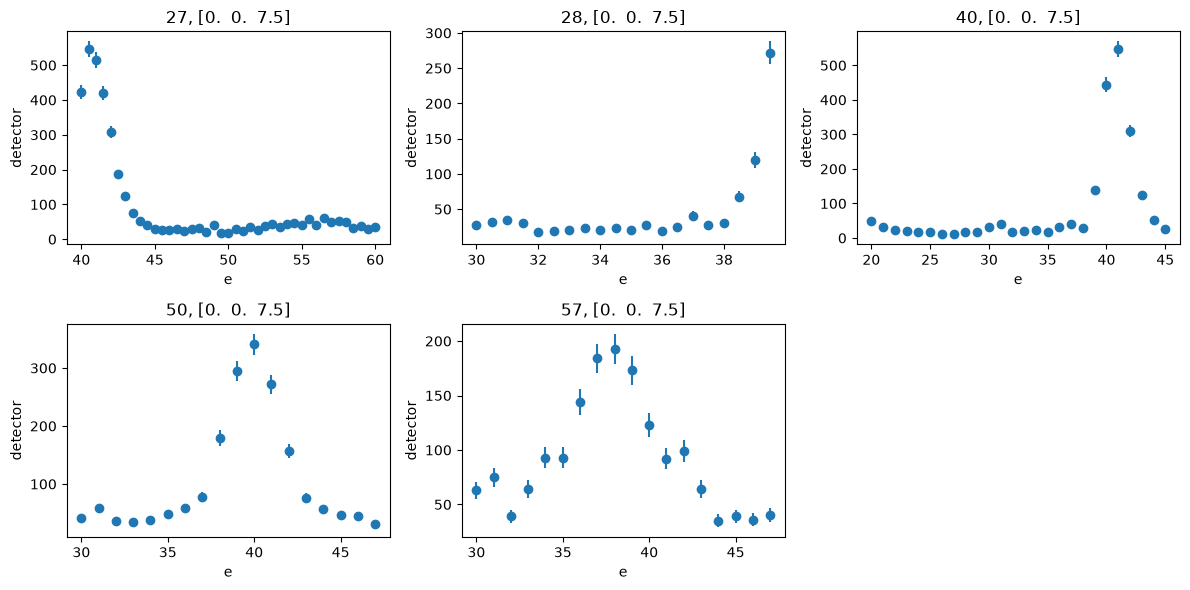

(None, None, None)

In [34]:
scan_list = list([27,28, 40,50,57])
tas.browse(scan_list, show_fits = False)

In [19]:
def get_uuid_from_scan_list(experiment, scan_list, IPTS=None, exp_num=None):
    """Resolve SPICE scan numbers to the uuids a ProcessOps takes, in the order given."""
    return [
        experiment.get_data_from_scan_number({"scan_num": scan_num, "IPTS": IPTS, "exp_num": exp_num}).uuid
        for scan_num in scan_list
    ]

<ErrorbarContainer object of 3 artists>

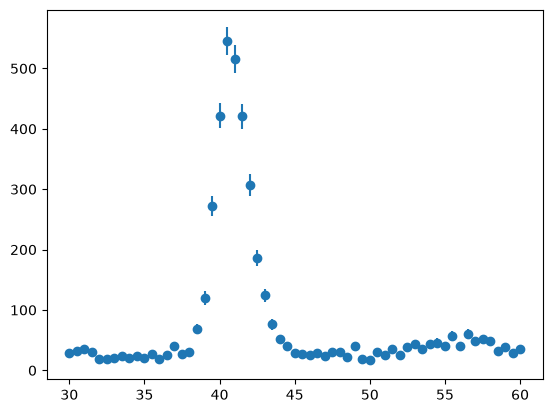

In [42]:
append_list = [27, 28]
tavi_data = tas.experiment.tavi_data
scan_list_uuids = get_uuid_from_scan_list(experiment=tas.experiment, scan_list=append_list)
from tavi.library.data.process_data import AppendOp, EqualStepRebinOps, ToleranceRebinOps
from matplotlib import pyplot as plt   

append_data = AppendOp(tavi_data=tavi_data, uuids=scan_list_uuids, columns=["e", "detector", "mcu"]).exec()
error = [np.sqrt(e) for e in append_data.data.detector]
plt.errorbar(append_data.data.e, append_data.data.detector, yerr=error, fmt = "o") 

<ErrorbarContainer object of 3 artists>

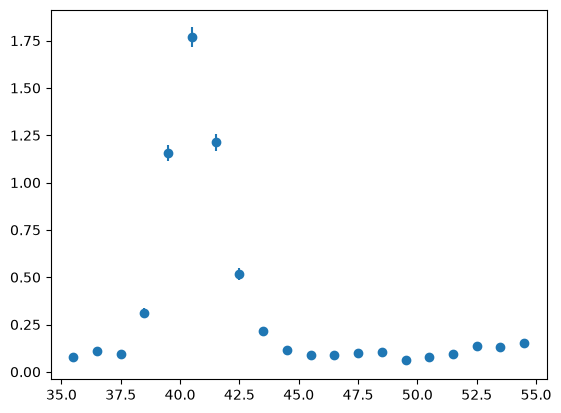

In [50]:
equal_step_rebin_data = EqualStepRebinOps(
    tavi_data=tavi_data, uuids=scan_list_uuids, columns=["e", "detector", "mcu"], step=1, start = 35, finish=55, norm="mcu"
).exec()
plt.errorbar(
    equal_step_rebin_data.data.e,
    equal_step_rebin_data.data.detector,
    yerr=equal_step_rebin_data.data.error,
    fmt="o",
)

<ErrorbarContainer object of 3 artists>

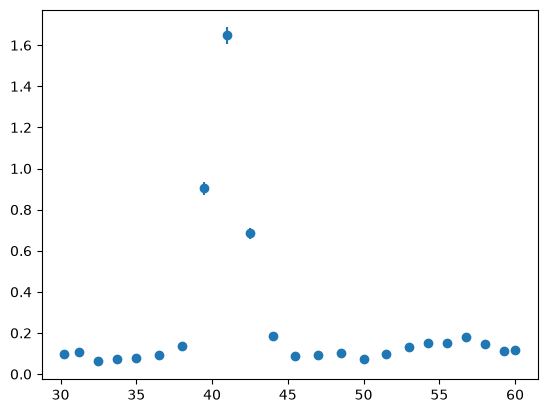

In [48]:
tol_rebin_data = ToleranceRebinOps(
    tavi_data=tavi_data, uuids=scan_list_uuids, columns=["e", "detector", "mcu"], tol=1,norm="mcu"
).exec()
plt.errorbar(
    tol_rebin_data.data.e,
    tol_rebin_data.data.detector,
    yerr=tol_rebin_data.data.error,
    fmt="o",
)